# 1- Importing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load IBM Telco Customer Churn dataset from Excel
df_telco = pd.read_excel('Telco_customer_churn.xlsx')

# Quick preview
print(f"Dataset shape: {df_telco.shape}")
print(f"Columns: {list(df_telco.columns)}")

Dataset shape: (7043, 33)
Columns: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


# 2-Data Cleaning

In [4]:
# Preview first few rows
df_telco.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [14]:
df_telco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customerid         7043 non-null   object 
 1   count              7043 non-null   int64  
 2   country            7043 non-null   object 
 3   state              7043 non-null   object 
 4   city               7043 non-null   object 
 5   zip_code           7043 non-null   int64  
 6   lat_long           7043 non-null   object 
 7   latitude           7043 non-null   float64
 8   longitude          7043 non-null   float64
 9   gender             7043 non-null   object 
 10  senior_citizen     7043 non-null   object 
 11  partner            7043 non-null   object 
 12  dependents         7043 non-null   object 
 13  tenure_months      7043 non-null   int64  
 14  phone_service      7043 non-null   object 
 15  multiple_lines     7043 non-null   object 
 16  internet_service   7043 

In [5]:
#a- fix Total Charges column (stored as object, convert to numeric)
#b- drop irrelevant columns: Count, Country, State, Lat Long, Latitude, Longitude
#c- standardize column names (lowercase, replace spaces with underscores)
#d- handle missing values in Total Charges
#e- create churn_flag column (binary: 1=churned, 0=retained)

In [16]:
#a- fix Total Charges column - convert to numeric (some rows have spaces)
df_telco['Total Charges'] = pd.to_numeric(df_telco['total_charges'], errors='coerce')

In [ ]:
#b- drop columns that are not useful for analysis
cols_to_drop = ['count', 'country', 'state', 'lat_long', 'latitude', 'longitude']
df_telco.drop(columns=cols_to_drop,axis=1, inplace=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customerid         7043 non-null   object 
 1   city               7043 non-null   object 
 2   zip_code           7043 non-null   int64  
 3   gender             7043 non-null   object 
 4   senior_citizen     7043 non-null   object 
 5   partner            7043 non-null   object 
 6   dependents         7043 non-null   object 
 7   tenure_months      7043 non-null   int64  
 8   phone_service      7043 non-null   object 
 9   multiple_lines     7043 non-null   object 
 10  internet_service   7043 non-null   object 
 11  online_security    7043 non-null   object 
 12  online_backup      7043 non-null   object 
 13  device_protection  7043 non-null   object 
 14  tech_support       7043 non-null   object 
 15  streaming_tv       7043 non-null   object 
 16  streaming_movies   7043 

In [22]:
#c- standardize column names: lowercase + replace spaces with underscores
df_telco.columns = df_telco.columns.str.lower().str.replace(' ', '_')
df_telco.head()

,customerid,city,zip_code,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,...,paperless_billing,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason,total_charges
0,3668-QPYBK,Los Angeles,90003,Male,No,No,No,2,Yes,No,...,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer,108.15
1,9237-HQITU,Los Angeles,90005,Female,No,No,Yes,2,Yes,No,...,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved,151.65
2,9305-CDSKC,Los Angeles,90006,Female,No,No,Yes,8,Yes,Yes,...,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved,820.50
3,7892-POOKP,Los Angeles,90010,Female,No,Yes,Yes,28,Yes,Yes,...,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved,3046.05
4,0280-XJGEX,Los Angeles,90015,Male,No,No,Yes,49,Yes,Yes,...,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices,5036.30


In [23]:
#d- handle missing values in total_charges
# Customers with 0 tenure likely have NaN total_charges — fill with 0
print("Missing values before fix:")
print(df_telco.isnull().sum()[df_telco.isnull().sum() > 0])

df_telco['total_charges'] = df_telco['total_charges'].fillna(0)

print("\nMissing values after fix:")
print(df_telco.isnull().sum()[df_telco.isnull().sum() > 0])

Missing values before fix:
churn_reason     5174
total_charges      11
dtype: int64

Missing values after fix:
churn_reason    5174
dtype: int64


In [24]:
#e- create churn_flag column (binary: 1 = churned, 0 = retained)
df_telco['churn_flag'] = np.where(df_telco['churn_label'] == 'Yes', 1, 0)

In [25]:
# Verify cleaned dataset
print(f"Shape: {df_telco.shape}")
df_telco.head(3)

Shape: (7043, 29)


,customerid,city,zip_code,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,...,payment_method,monthly_charges,total_charges,churn_label,churn_value,churn_score,cltv,churn_reason,total_charges,churn_flag
0,3668-QPYBK,Los Angeles,90003,Male,No,No,No,2,Yes,No,...,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer,108.15,1
1,9237-HQITU,Los Angeles,90005,Female,No,No,Yes,2,Yes,No,...,Electronic check,70.70,151.65,Yes,1,67,2701,Moved,151.65,1
2,9305-CDSKC,Los Angeles,90006,Female,No,No,Yes,8,Yes,Yes,...,Electronic check,99.65,820.5,Yes,1,86,5372,Moved,820.50,1


# 3- Feature Engineering and data analysis

In [26]:
# create a new column using existing column — tenure buckets
df_telco['tenure_bucket'] = pd.cut(
    df_telco['tenure_months'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12m', '13-24m', '25-48m', '49-72m']
)
df_telco[['tenure_months', 'tenure_bucket']].head(10)

,tenure_months,tenure_bucket
0,2,0-12m
1,2,0-12m
2,8,0-12m
3,28,25-48m
4,49,49-72m
5,10,0-12m
6,1,0-12m
7,1,0-12m
8,47,25-48m
9,1,0-12m


In [27]:
# 11 churn risk - create a column using existing churn_score column

conditions = [
    (df_telco['churn_score'] < 50),
    (df_telco['churn_score'] >= 50) & (df_telco['churn_score'] < 70),
    (df_telco['churn_score'] >= 70)
]
choices = ['low', 'med', 'high']
df_telco['churn_risk'] = np.select(conditions, choices, default='unknown')

df_telco[['churn_risk', 'churn_score']].head()

,churn_risk,churn_score
0,high,86
1,med,67
2,high,86
3,high,84
4,high,89


In [28]:
df_telco.to_csv('exported_churn_data.csv', index=False)

# Data Analysis


#1 churn rate


In [29]:
churn_rate = df_telco['churn_flag'].mean() * 100
print("churn rate =", round(churn_rate, 2), '%')


churn rate = 26.54 %


#2- retention rate

In [30]:
retention_rate = 100 - churn_rate
print("retention_rate =", round(retention_rate, 2), '%')

retention_rate = 73.46 %


In [31]:
#3- churn by contract type
churn_by_contract = df_telco.groupby('contract')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct(in %)')
print(churn_by_contract)

         contract  churn_rate_pct(in %)
0  Month-to-month                 42.71
1        One year                 11.27
2        Two year                  2.83


In [18]:
#4- a churn by internet service
#4- b churn by payment method


In [32]:
churn_by_internet = df_telco.groupby('internet_service')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
print(churn_by_internet)

  internet_service  churn_rate_pct
0              DSL           18.96
1      Fiber optic           41.89
2               No            7.40


In [33]:
churn_by_city = df_telco.groupby('city')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
churn_by_city = churn_by_city.sort_values('churn_rate_pct', ascending=False)
print("Top 10 cities by churn rate:")
print(churn_by_city.head(20))

Top 10 cities by churn rate:
                  city  churn_rate_pct
1118        Wrightwood           100.0
1014            Tipton           100.0
1028           Truckee           100.0
1036             Twain           100.0
466       Johannesburg           100.0
345         Fort Jones           100.0
942        Smith River           100.0
590           Maricopa           100.0
105      Boulder Creek           100.0
842          Riverbank           100.0
297           Eldridge           100.0
958   South Lake Tahoe           100.0
920             Seeley            80.0
743      Panorama City            80.0
451       Indian Wells            80.0
870          San Dimas            80.0
393             Grimes            75.0
1090         Wheatland            75.0
262             Dinuba            75.0
254              Delhi            75.0


In [34]:
#5- ARPU (avg revenue per user)
arpu = df_telco['monthly_charges'].mean()
print(f"ARPU : {round(arpu, 2)}")


ARPU : 64.76


In [35]:
# 6- avg customer tenure
avg_tenure = df_telco['tenure_months'].mean()
print(f'avg tenure (months) = {round(avg_tenure, 1)}')

avg tenure (months) = 32.4


In [36]:
df_telco['cltv']

0       3239
1       2701
2       5372
3       5003
4       5340
        ... 
7038    5306
7039    2140
7040    5560
7041    2793
7042    5097
Name: cltv, Length: 7043, dtype: int64

In [23]:
#7- revenue at risk - revenue lost from churned users
revenue_at_risk = df_telco.loc[df_telco['churn_flag'] == 1, 'monthly_charges'].sum()
print("revenue at risk (monthly $):", round(revenue_at_risk, 2))

revenue at risk (monthly $): 139130.85


In [37]:
#8- CLTV at risk
cltv_at_risk = df_telco.loc[df_telco['churn_flag'] == 1, 'cltv'].sum()
print("CLTV at risk ($):", round(cltv_at_risk, 2))

CLTV at risk ($): 7755256


In [25]:
#9- churn by contract type (detailed breakdown)
contract_summary = df_telco.groupby('contract').agg(
    total=('churn_flag', 'count'),
    churned=('churn_flag', 'sum'),
    mrr=('monthly_charges', 'sum')
).assign(churn_rate=lambda x: (x['churned'] / x['total'] * 100).round(1))
print(contract_summary)

                total  churned        mrr  churn_rate
contract                                             
Month-to-month   3875     1655  257294.15        42.7
One year         1473      166   95816.60        11.3
Two year         1695       48  103005.85         2.8


In [26]:
# correlation between churn_score and churn_flag
correlation = df_telco['churn_score'].corr(df_telco['churn_flag'])
print("correlation between churn_score and churn_flag =", round(correlation, 2))


correlation between churn_score and churn_flag = 0.66


# visualisation using matplotlib

In [39]:
df_visual = df_telco.copy()

In [40]:
df_visual.columns

Index(['customerid', 'city', 'zip_code', 'gender', 'senior_citizen', 'partner',
       'dependents', 'tenure_months', 'phone_service', 'multiple_lines',
       'internet_service', 'online_security', 'online_backup',
       'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
       'contract', 'paperless_billing', 'payment_method', 'monthly_charges',
       'total_charges', 'churn_label', 'churn_value', 'churn_score', 'cltv',
       'churn_reason', 'total_charges', 'churn_flag', 'tenure_bucket',
       'churn_risk'],
      dtype='object')

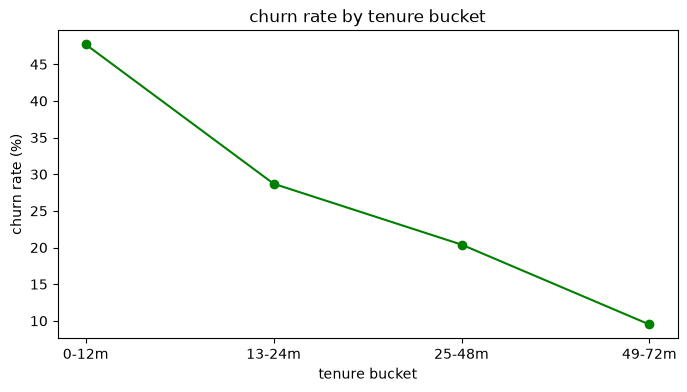

In [43]:
# 4.1 churn by tenure bucket (time series style)
churn_trend = df_visual.groupby('tenure_bucket', observed=True)['churn_flag'].mean().mul(100).round(1)
plt.figure(figsize=(8, 4))
plt.plot(churn_trend.index.astype('str'), churn_trend.values, color='green', marker='o')
plt.xlabel('tenure bucket')
plt.ylabel('churn rate (%)')
plt.title('churn rate by tenure bucket')
plt.show()

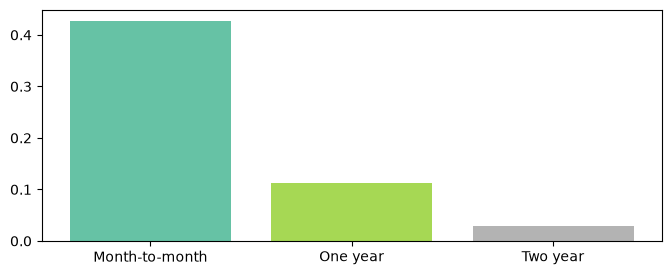

In [44]:
#4.2 churn by contract type
churn_contract = df_visual.groupby('contract')['churn_flag'].mean()
plt.figure(figsize=(8, 3))
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_contract)))
plt.bar(churn_contract.index, churn_contract.values, color=colors)
plt.show()

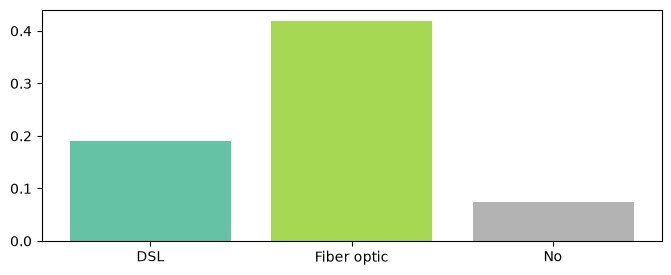

In [45]:
# 4.3 churn by internet service
churn_internet = df_visual.groupby('internet_service')['churn_flag'].mean()
plt.figure(figsize=(8, 3))
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_internet)))
plt.bar(churn_internet.index, churn_internet.values, color=colors)
plt.show()

# visulisation using seaborn

In [48]:
# encoding -convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'city', 'zip_code', 'gender', 'senior_citizen', 'partner',
       'dependents', 'tenure_months', 'phone_service', 'multiple_lines',
       'internet_service', 'online_security', 'online_backup',
       'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
       'contract', 'paperless_billing', 'payment_method', 'monthly_charges',
       'total_charges', 'churn_label', 'churn_value', 'churn_score', 'cltv',
       'churn_reason', 'total_charges', 'churn_flag', 'tenure_bucket',
       'churn_risk'],
      dtype='object')

In [49]:
# df_encoded
# wrong method of encoding
"""df_encoded = df_visual[['contract','internet_service','churn_score','churn_flag','churn_risk','senior_citizen']].head()
categorical_columns = ['contract','internet_service','churn_risk']
for col in categorical_columns:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes
df_encoded"""


"df_encoded = df_visual[['contract','internet_service','churn_score','churn_flag','churn_risk','senior_citizen']].head()\ncategorical_columns = ['contract','internet_service','churn_risk']\nfor col in categorical_columns:\n    df_encoded[col] = df_encoded[col].astype('category').cat.codes\ndf_encoded"

In [50]:
# correct method of encoding
df_encoded = df_visual[['contract', 'internet_service', 'churn_score', 'churn_flag', 'churn_risk', 'senior_citizen']].copy()
order_mapping = {
    'contract': ['Month-to-month', 'One year', 'Two year'],
    'internet_service': ['No', 'DSL', 'Fiber optic'],
    'churn_risk': ['low', 'med', 'high']
}
for col, order in order_mapping.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes
df_encoded['senior_citizen'] = df_encoded['senior_citizen'].map({'Yes': 1, 'No': 0})

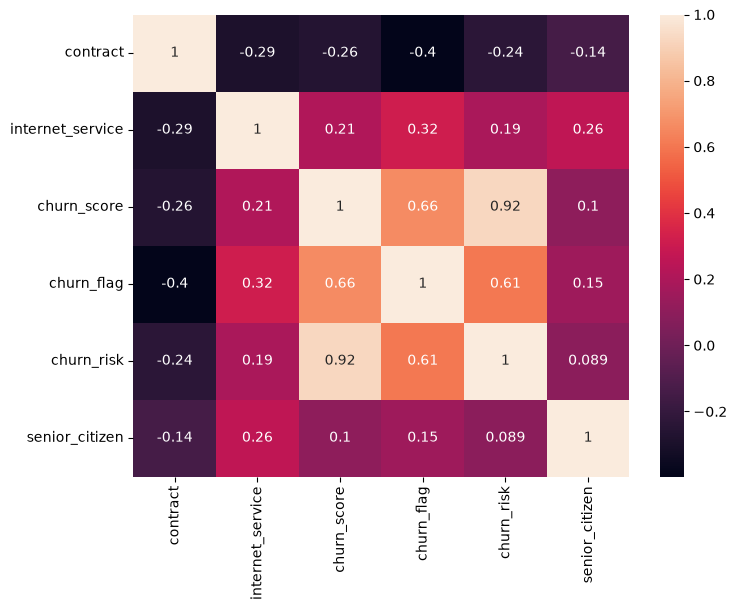

In [51]:
#heapmap (correlation matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(df_encoded.corr(), annot=True)
plt.show()

In [52]:
""" 0 to 1 -> positive correlation
    -1 to 0 -> negative correlation"""

' 0 to 1 -> positive correlation\n    -1 to 0 -> negative correlation'

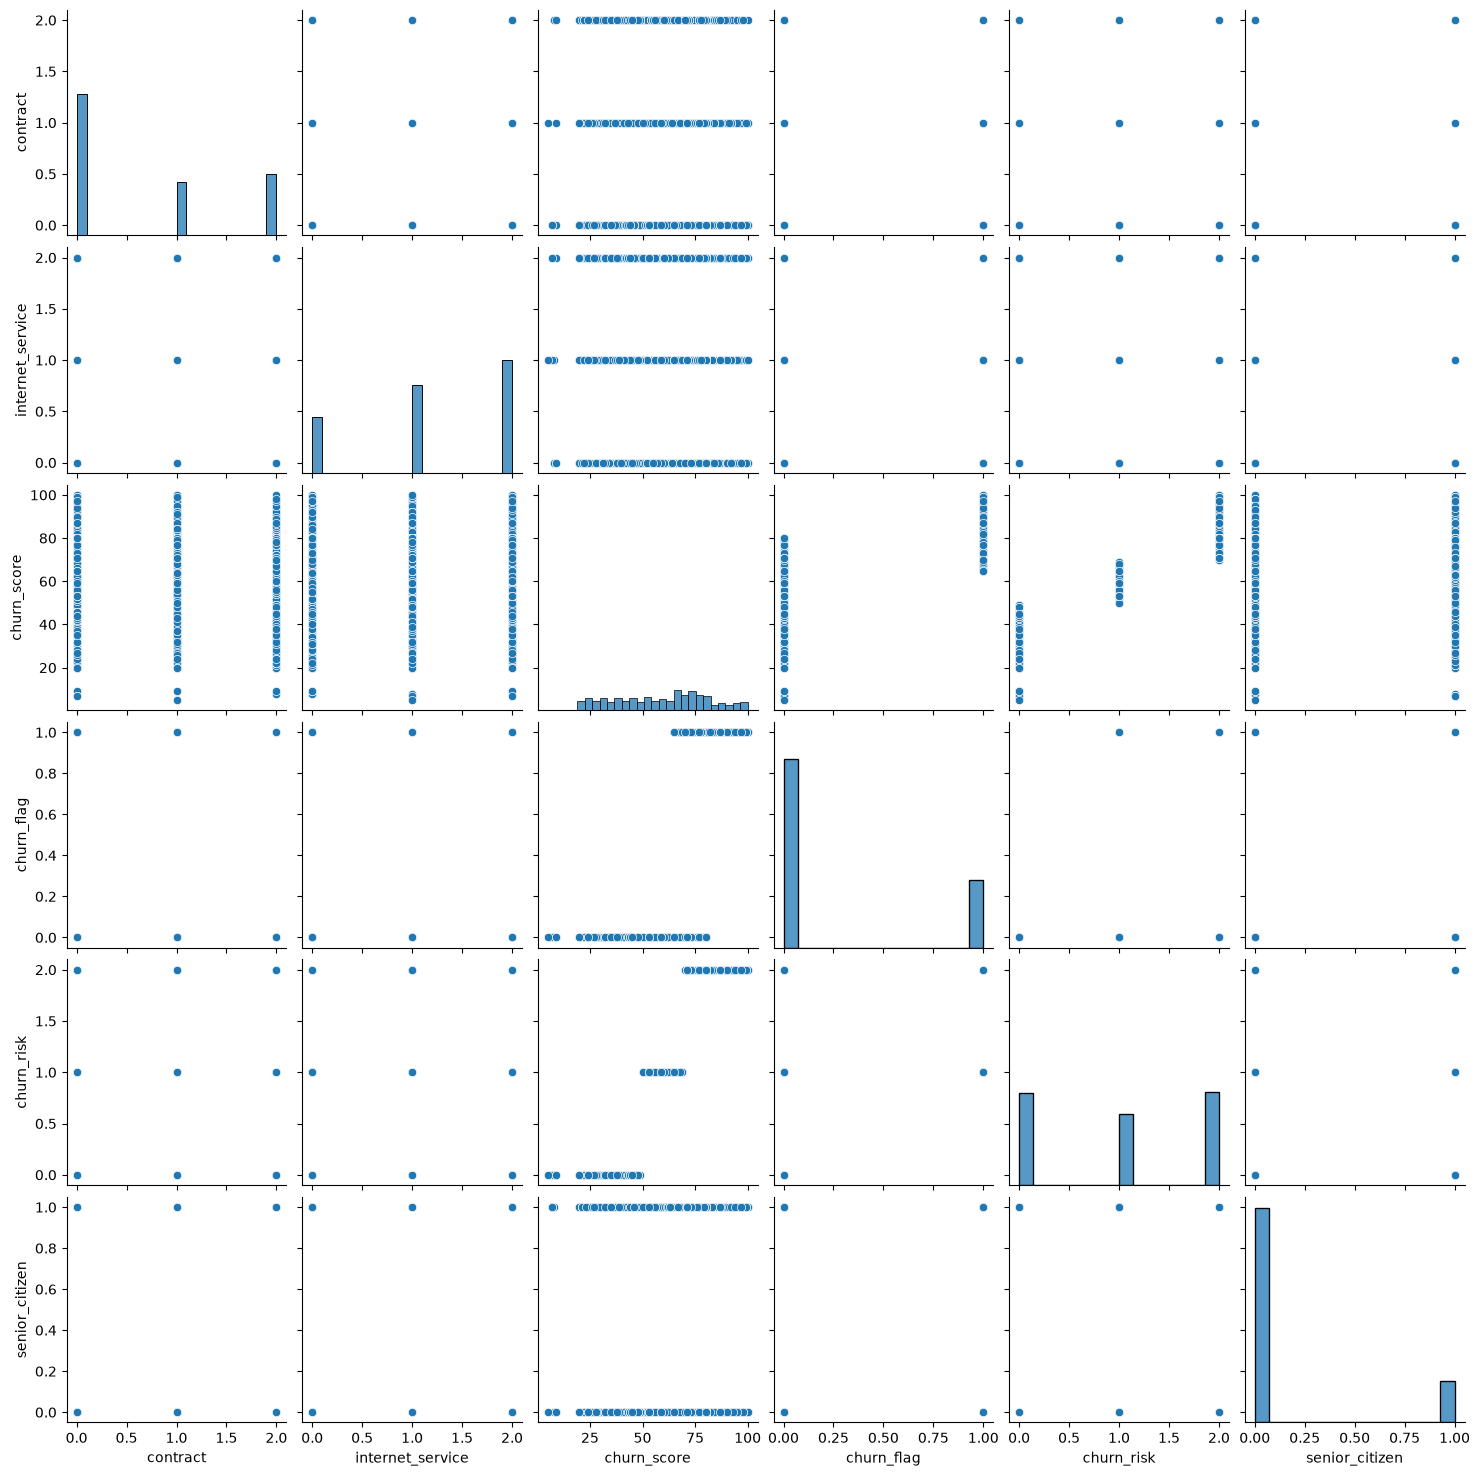

In [53]:
sns.pairplot(df_encoded)
plt.show()